In [2]:
import os

# Display the current working directory
print("Current working directory:")
print(os.getcwd())

# Display the files and folders in this location
print("\nFiles and folders:")
print(os.listdir())

Current working directory:
c:\Users\abhiv\Desktop\Customer engagement retention analytics

Files and folders:
['customer_engagement_analysis.ipynb', 'European_Bank(2).csv', 'project 3 documentation.docx']


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("European_Bank(2).csv")

# Display the first five rows
df.head()

,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check duplicate customer IDs
print(
    "Duplicate Customer IDs:",
    df["CustomerId"].duplicated().sum()
)

Dataset Shape: (10000, 14)

Column Names:
['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Missing Values:
Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Duplicate Rows: 0
Duplicate Customer IDs: 0


In [5]:
# Calculate total customers
total_customers = len(df)

# Count churned and retained customers
churned_customers = (df["Exited"] == 1).sum()
retained_customers = (df["Exited"] == 0).sum()

# Calculate overall churn rate
overall_churn_rate = (churned_customers / total_customers) * 100

# Display results
print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print(f"Overall Churn Rate: {overall_churn_rate:.2f}%")

Total Customers: 10000
Churned Customers: 2037
Retained Customers: 7963
Overall Churn Rate: 20.37%


In [6]:
# Calculate churn statistics by engagement status
engagement_summary = df.groupby("IsActiveMember").agg(
    Total_Customers=("CustomerId", "count"),
    Churned_Customers=("Exited", "sum"),
    Average_Balance=("Balance", "mean"),
    Average_Salary=("EstimatedSalary", "mean")
).reset_index()

# Calculate churn rate
engagement_summary["Churn_Rate"] = (
    engagement_summary["Churned_Customers"]
    / engagement_summary["Total_Customers"]
) * 100

# Add readable engagement labels
engagement_summary["Engagement_Status"] = (
    engagement_summary["IsActiveMember"]
    .map({1: "Active", 0: "Inactive"})
)

# Display the summary
engagement_summary

,IsActiveMember,Total_Customers,Churned_Customers,Average_Balance,Average_Salary,Churn_Rate,Engagement_Status
0,0,4849,1302,77134.376863,100767.203854,26.850897,Inactive
1,1,5151,735,75875.422145,99452.965894,14.269074,Active


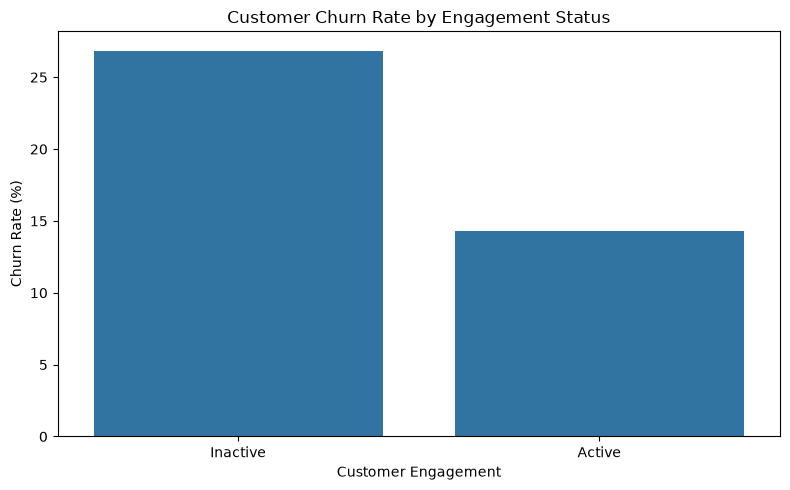

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate churn rate for each engagement group
engagement_churn = (
    df.groupby("IsActiveMember")["Exited"]
    .mean()
    .mul(100)
    .reset_index()
)

# Replace numeric values with readable labels
engagement_churn["Engagement_Status"] = (
    engagement_churn["IsActiveMember"]
    .map({1: "Active", 0: "Inactive"})
)

# Create the chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=engagement_churn,
    x="Engagement_Status",
    y="Exited"
)

plt.title("Customer Churn Rate by Engagement Status")
plt.xlabel("Customer Engagement")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

In [8]:
# Analyze customer retention by number of products

product_summary = df.groupby("NumOfProducts").agg(
    Total_Customers=("CustomerId", "count"),
    Churned_Customers=("Exited", "sum"),
    Average_Balance=("Balance", "mean"),
    Active_Customers=("IsActiveMember", "sum")
).reset_index()

# Calculate churn rate
product_summary["Churn_Rate"] = (
    product_summary["Churned_Customers"]
    / product_summary["Total_Customers"]
) * 100

# Calculate active customer percentage
product_summary["Active_Customer_Percentage"] = (
    product_summary["Active_Customers"]
    / product_summary["Total_Customers"]
) * 100

# Display results
product_summary.round(2)

,NumOfProducts,Total_Customers,Churned_Customers,Average_Balance,Active_Customers,Churn_Rate,Active_Customer_Percentage
0,1,5084,1409,98551.87,2563,27.71,50.41
1,2,4590,348,51879.15,2446,7.58,53.29
2,3,266,220,75458.33,113,82.71,42.48
3,4,60,60,93733.14,29,100.00,48.33


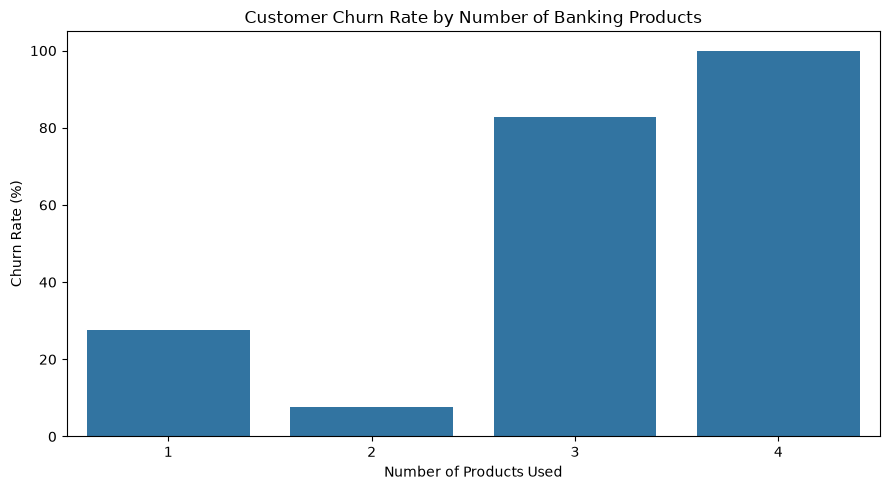

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=product_summary,
    x="NumOfProducts",
    y="Churn_Rate"
)

plt.title("Customer Churn Rate by Number of Banking Products")
plt.xlabel("Number of Products Used")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

In [10]:
# Classify customers by product usage

df["Product_Category"] = df["NumOfProducts"].apply(
    lambda x: "Single Product" if x == 1 else "Multiple Products"
)

# Calculate retention statistics
product_category_summary = df.groupby("Product_Category").agg(
    Total_Customers=("CustomerId", "count"),
    Churned_Customers=("Exited", "sum")
).reset_index()

product_category_summary["Churn_Rate"] = (
    product_category_summary["Churned_Customers"]
    / product_category_summary["Total_Customers"]
) * 100

product_category_summary["Retention_Rate"] = (
    100 - product_category_summary["Churn_Rate"]
)

product_category_summary.round(2)

,Product_Category,Total_Customers,Churned_Customers,Churn_Rate,Retention_Rate
0,Multiple Products,4916,628,12.77,87.23
1,Single Product,5084,1409,27.71,72.29


In [11]:
# Calculate the 75th percentile of customer balances
balance_threshold = df["Balance"].quantile(0.75)

print("High-Balance Threshold:", round(balance_threshold, 2))

# Identify high-balance customers
df["High_Balance"] = df["Balance"] >= balance_threshold

print(
    "Number of High-Balance Customers:",
    df["High_Balance"].sum()
)

High-Balance Threshold: 127644.24
Number of High-Balance Customers: 2500


In [12]:
# Identify high-balance customers who are inactive
at_risk_premium = df[
    (df["High_Balance"] == True) &
    (df["IsActiveMember"] == 0)
].copy()

print("High-Balance Inactive Customers:", len(at_risk_premium))

# Calculate their churn rate
if len(at_risk_premium) > 0:
    at_risk_churn_rate = at_risk_premium["Exited"].mean() * 100
    print(f"Churn Rate: {at_risk_churn_rate:.2f}%")

# Display sample records
at_risk_premium[
    [
        "CustomerId",
        "Geography",
        "Balance",
        "EstimatedSalary",
        "IsActiveMember",
        "Exited"
    ]
].head(10)

High-Balance Inactive Customers: 1247
Churn Rate: 30.47%


,CustomerId,Geography,Balance,EstimatedSalary,IsActiveMember,Exited
2,15619304,France,159660.80,113931.57,0,1
16,15737452,Germany,132602.88,5097.67,0,1
35,15794171,France,134264.04,27822.99,0,1
43,15755196,France,131394.56,194365.76,0,1
51,15768193,Germany,146050.97,86424.57,0,0
56,15630053,France,127864.40,87107.57,0,0
60,15651280,Germany,136857.00,84509.57,0,0
61,15773469,Germany,152328.88,126494.82,0,0
70,15703793,Germany,133745.44,28373.86,0,1
75,15780961,France,178718.19,22388.00,0,0


In [13]:
# Create customer segments based on balance and activity

df["Customer_Segment"] = np.select(
    [
        (df["High_Balance"]) & (df["IsActiveMember"] == 1),
        (df["High_Balance"]) & (df["IsActiveMember"] == 0),
        (~df["High_Balance"]) & (df["IsActiveMember"] == 1),
        (~df["High_Balance"]) & (df["IsActiveMember"] == 0)
    ],
    [
        "High Balance - Active",
        "High Balance - Inactive",
        "Lower Balance - Active",
        "Lower Balance - Inactive"
    ],
    default="Other"
)

# Summarize each segment
segment_summary = df.groupby("Customer_Segment").agg(
    Total_Customers=("CustomerId", "count"),
    Churned_Customers=("Exited", "sum"),
    Average_Balance=("Balance", "mean"),
    Average_Salary=("EstimatedSalary", "mean")
).reset_index()

segment_summary["Churn_Rate"] = (
    segment_summary["Churned_Customers"]
    / segment_summary["Total_Customers"]
) * 100

segment_summary.round(2)

,Customer_Segment,Total_Customers,Churned_Customers,Average_Balance,Average_Salary,Churn_Rate
0,High Balance - Active,1253,212,149243.04,99973.22,16.92
1,High Balance - Inactive,1247,380,148857.68,101338.72,30.47
2,Lower Balance - Active,3898,523,52291.63,99285.73,13.42
3,Lower Balance - Inactive,3602,922,52304.02,100569.35,25.60


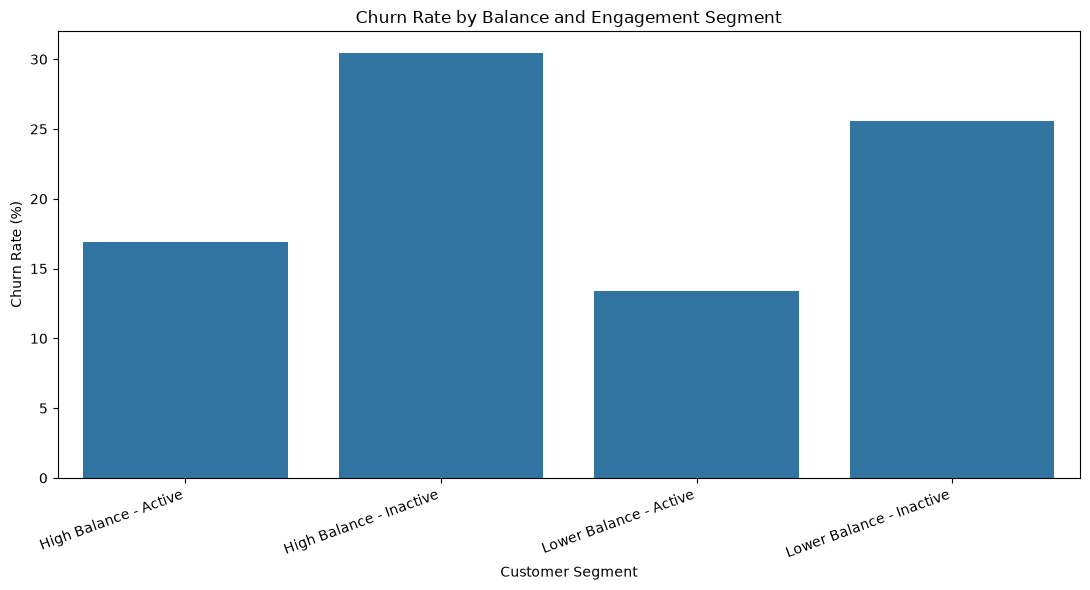

In [14]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=segment_summary,
    x="Customer_Segment",
    y="Churn_Rate"
)

plt.title("Churn Rate by Balance and Engagement Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

In [15]:
# Calculate retention rates for active and inactive customers

engagement_retention = df.groupby("IsActiveMember")["Exited"].apply(
    lambda x: (x == 0).mean() * 100
)

active_retention = engagement_retention.get(1, 0)
inactive_retention = engagement_retention.get(0, 0)

print(f"Active Customer Retention Rate: {active_retention:.2f}%")
print(f"Inactive Customer Retention Rate: {inactive_retention:.2f}%")

# Engagement Retention Ratio
if inactive_retention > 0:
    engagement_retention_ratio = active_retention / inactive_retention
    print(f"Engagement Retention Ratio: {engagement_retention_ratio:.2f}")
else:
    engagement_retention_ratio = np.nan
    print("Engagement Retention Ratio cannot be calculated.")

Active Customer Retention Rate: 85.73%
Inactive Customer Retention Rate: 73.15%
Engagement Retention Ratio: 1.17


In [16]:
# Calculate Product Depth Index

retained_customers = df[df["Exited"] == 0]

product_depth_index = retained_customers["NumOfProducts"].mean()

print(f"Product Depth Index: {product_depth_index:.2f}")

Product Depth Index: 1.54


In [17]:
product_depth_comparison = df.groupby("Exited").agg(
    Customer_Count=("CustomerId", "count"),
    Average_Products=("NumOfProducts", "mean")
).reset_index()

product_depth_comparison["Customer_Status"] = (
    product_depth_comparison["Exited"]
    .map({0: "Retained", 1: "Churned"})
)

product_depth_comparison.round(2)

,Exited,Customer_Count,Average_Products,Customer_Status
0,0,7963,1.54,Retained
1,1,2037,1.48,Churned


In [18]:
# Identify high-balance customers
high_balance_customers = df[df["High_Balance"]]

# Calculate the high-balance disengagement rate
if len(high_balance_customers) > 0:
    high_balance_disengagement_rate = (
        (high_balance_customers["IsActiveMember"] == 0).mean() * 100
    )
else:
    high_balance_disengagement_rate = np.nan

print(
    f"High-Balance Disengagement Rate: "
    f"{high_balance_disengagement_rate:.2f}%"
)

High-Balance Disengagement Rate: 49.88%


In [19]:
# Filter customers who own a credit card
credit_card_customers = df[df["HasCrCard"] == 1]

# Calculate their retention rate
if len(credit_card_customers) > 0:
    credit_card_stickiness_score = (
        (credit_card_customers["Exited"] == 0).mean() * 100
    )
else:
    credit_card_stickiness_score = np.nan

print(
    f"Credit Card Stickiness Score: "
    f"{credit_card_stickiness_score:.2f}%"
)

Credit Card Stickiness Score: 79.82%


In [20]:
# Normalize product usage to a 0-100 scale
max_products = df["NumOfProducts"].max()

if max_products > 0:
    df["Product_Usage_Score"] = (
        df["NumOfProducts"] / max_products
    ) * 100
else:
    df["Product_Usage_Score"] = 0

# Convert activity status into a 0-100 score
df["Engagement_Score"] = df["IsActiveMember"] * 100

# Calculate Relationship Strength Index
df["Relationship_Strength_Index"] = (
    0.50 * df["Engagement_Score"]
    + 0.50 * df["Product_Usage_Score"]
)

# Display sample results
df[
    [
        "CustomerId",
        "IsActiveMember",
        "NumOfProducts",
        "Engagement_Score",
        "Product_Usage_Score",
        "Relationship_Strength_Index",
        "Exited"
    ]
].head(10)

,CustomerId,IsActiveMember,NumOfProducts,Engagement_Score,Product_Usage_Score,Relationship_Strength_Index,Exited
0,15634602,1,1,100,25.0,62.5,1
1,15647311,1,1,100,25.0,62.5,0
2,15619304,0,3,0,75.0,37.5,1
3,15701354,0,2,0,50.0,25.0,0
4,15737888,1,1,100,25.0,62.5,0
5,15574012,0,2,0,50.0,25.0,1
6,15592531,1,2,100,50.0,75.0,0
7,15656148,0,4,0,100.0,50.0,1
8,15792365,1,2,100,50.0,75.0,0
9,15592389,1,1,100,25.0,62.5,0


In [21]:
from pathlib import Path

# Create the output folder if it doesn't exist
output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

print("Output folder is ready:", output_dir.resolve())

Output folder is ready: C:\Users\abhiv\Desktop\Customer engagement retention analytics\outputs


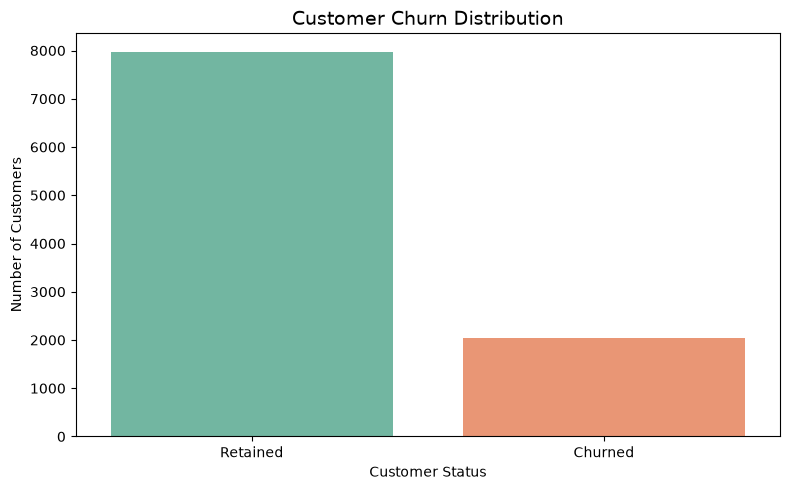

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Exited",
    hue="Exited",
    order=[0, 1],
    palette="Set2",
    legend=False
)

ax.set_xticks([0, 1], ["Retained", "Churned"])

plt.title("Customer Churn Distribution", fontsize=14)
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.savefig(
    output_dir / "01_customer_churn_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

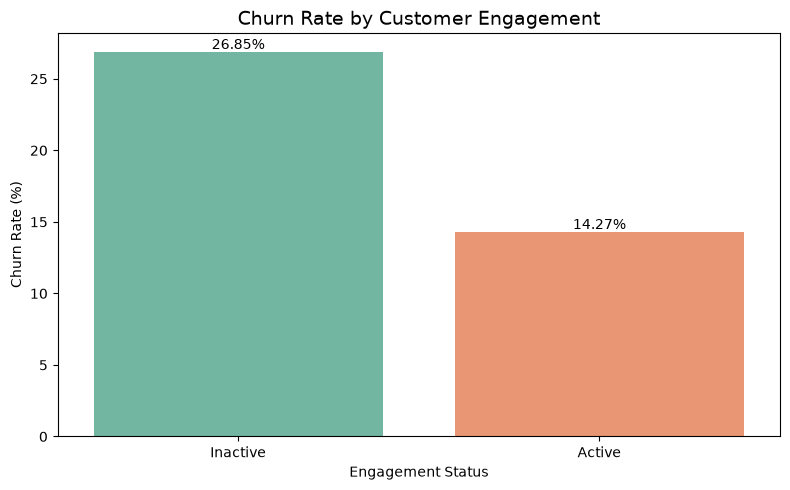

In [23]:
engagement_chart = df.groupby("IsActiveMember").agg(
    Total_Customers=("CustomerId", "count"),
    Churn_Rate=("Exited", "mean")
).reset_index()

engagement_chart["Churn_Rate"] *= 100

engagement_chart["Engagement_Status"] = (
    engagement_chart["IsActiveMember"]
    .map({1: "Active", 0: "Inactive"})
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=engagement_chart,
    x="Engagement_Status",
    y="Churn_Rate",
    hue="Engagement_Status",
    palette="Set2",
    legend=False
)

plt.title("Churn Rate by Customer Engagement", fontsize=14)
plt.xlabel("Engagement Status")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.savefig(
    output_dir / "02_churn_by_engagement.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

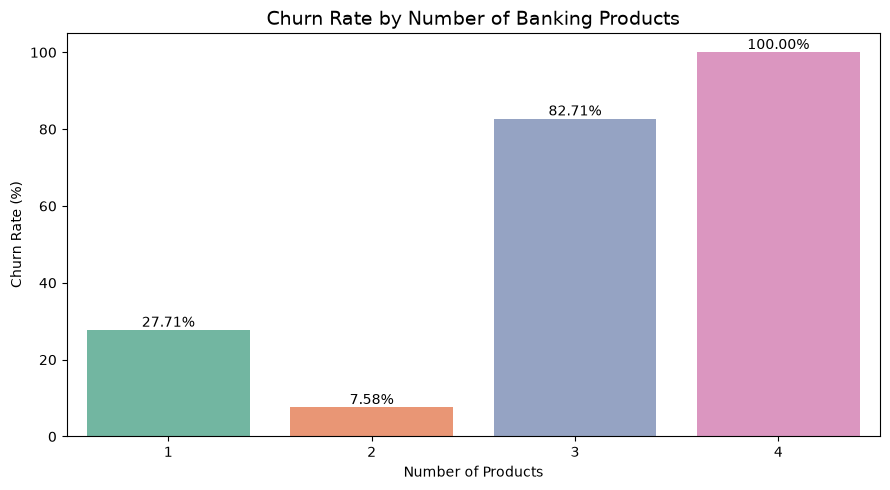

In [24]:
product_chart = df.groupby("NumOfProducts").agg(
    Total_Customers=("CustomerId", "count"),
    Churn_Rate=("Exited", "mean")
).reset_index()

product_chart["Churn_Rate"] *= 100

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=product_chart,
    x="NumOfProducts",
    y="Churn_Rate",
    hue="NumOfProducts",
    palette="Set2",
    legend=False
)

plt.title("Churn Rate by Number of Banking Products", fontsize=14)
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.savefig(
    output_dir / "03_churn_by_product_count.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

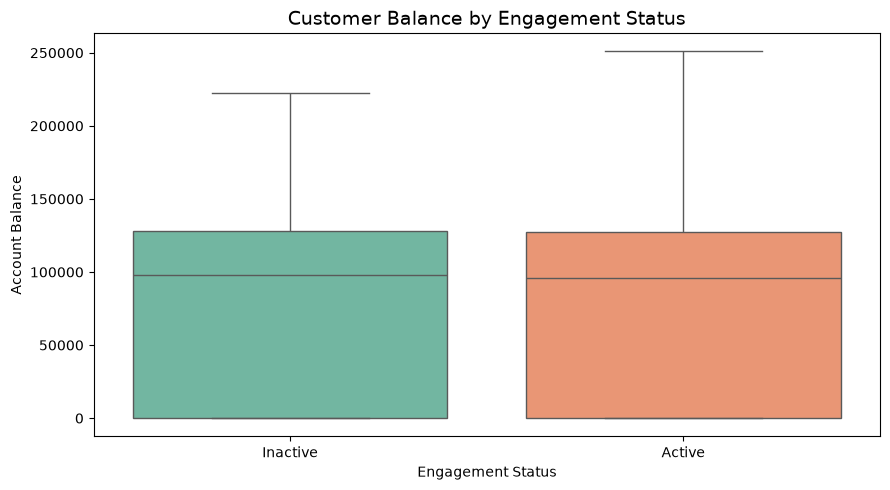

In [25]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="IsActiveMember",
    y="Balance",
    hue="IsActiveMember",
    palette="Set2",
    legend=False
)

plt.title("Customer Balance by Engagement Status", fontsize=14)
plt.xlabel("Engagement Status")
plt.ylabel("Account Balance")

plt.xticks([0, 1], ["Inactive", "Active"])

plt.tight_layout()
plt.savefig(
    output_dir / "04_balance_by_engagement.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

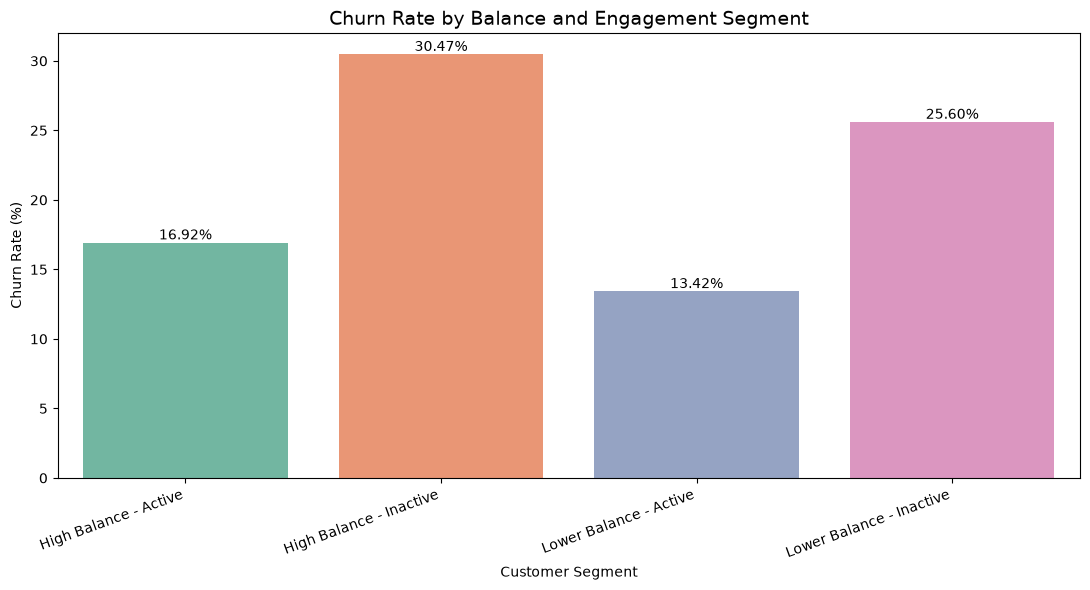

In [26]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=segment_summary,
    x="Customer_Segment",
    y="Churn_Rate",
    hue="Customer_Segment",
    palette="Set2",
    legend=False
)

plt.title("Churn Rate by Balance and Engagement Segment", fontsize=14)
plt.xlabel("Customer Segment")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.savefig(
    output_dir / "05_churn_by_customer_segment.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [27]:
# List all saved visualization files

for file in sorted(output_dir.glob("*.png")):
    print(file.name)

01_customer_churn_distribution.png
02_churn_by_engagement.png
03_churn_by_product_count.png
04_balance_by_engagement.png
05_churn_by_customer_segment.png


In [28]:
# Customer retention analysis by engagement status

retention_summary = df.groupby("IsActiveMember").agg(
    Total_Customers=("CustomerId", "count"),
    Retained_Customers=("Exited", lambda x: (x == 0).sum()),
    Churned_Customers=("Exited", lambda x: (x == 1).sum())
).reset_index()

retention_summary["Retention_Rate"] = (
    retention_summary["Retained_Customers"]
    / retention_summary["Total_Customers"]
) * 100

retention_summary["Churn_Rate"] = (
    retention_summary["Churned_Customers"]
    / retention_summary["Total_Customers"]
) * 100

retention_summary["Engagement_Status"] = (
    retention_summary["IsActiveMember"]
    .map({1: "Active", 0: "Inactive"})
)

retention_summary = retention_summary[
    [
        "Engagement_Status",
        "Total_Customers",
        "Retained_Customers",
        "Churned_Customers",
        "Retention_Rate",
        "Churn_Rate"
    ]
]

retention_summary.round(2)

,Engagement_Status,Total_Customers,Retained_Customers,Churned_Customers,Retention_Rate,Churn_Rate
0,Inactive,4849,3547,1302,73.15,26.85
1,Active,5151,4416,735,85.73,14.27


In [29]:
# Identify high-value disengaged customers

# Calculate the 75th percentile of customer balances
balance_threshold = df["Balance"].quantile(0.75)

# Select customers with high balances who are inactive
high_value_disengaged = df[
    (df["Balance"] >= balance_threshold) &
    (df["IsActiveMember"] == 0)
].copy()

# Calculate important statistics
total_disengaged = len(high_value_disengaged)

churned_disengaged = (
    high_value_disengaged["Exited"] == 1
).sum()

disengaged_churn_rate = (
    churned_disengaged / total_disengaged * 100
    if total_disengaged > 0 else 0
)

print("HIGH-VALUE DISENGAGED CUSTOMER ANALYSIS")
print("-" * 45)
print(f"High-balance threshold: {balance_threshold:.2f}")
print(f"Total high-value disengaged customers: {total_disengaged}")
print(f"Customers who have churned: {churned_disengaged}")
print(f"Churn rate in this group: {disengaged_churn_rate:.2f}%")

HIGH-VALUE DISENGAGED CUSTOMER ANALYSIS
---------------------------------------------
High-balance threshold: 127644.24
Total high-value disengaged customers: 1247
Customers who have churned: 380
Churn rate in this group: 30.47%


In [30]:
# Display selected customer details

high_value_disengaged[
    [
        "CustomerId",
        "Geography",
        "Age",
        "Balance",
        "NumOfProducts",
        "IsActiveMember",
        "Exited"
    ]
].head(10)

,CustomerId,Geography,Age,Balance,NumOfProducts,IsActiveMember,Exited
2,15619304,France,42,159660.80,3,0,1
16,15737452,Germany,58,132602.88,1,0,1
35,15794171,France,45,134264.04,1,0,1
43,15755196,France,49,131394.56,1,0,1
51,15768193,Germany,36,146050.97,2,0,0
56,15630053,France,45,127864.40,1,0,0
60,15651280,Germany,35,136857.00,1,0,0
61,15773469,Germany,27,152328.88,2,0,0
70,15703793,Germany,58,133745.44,4,0,1
75,15780961,France,21,178718.19,2,0,0


In [31]:
# Relationship Strength Index (RSI)

# Engagement score: 100 for active customers, 0 for inactive customers
df["Engagement_Score"] = df["IsActiveMember"] * 100

# Product usage score scaled from 0 to 100
max_products = df["NumOfProducts"].max()

df["Product_Usage_Score"] = (
    df["NumOfProducts"] / max_products
) * 100

# Calculate Relationship Strength Index
df["Relationship_Strength_Index"] = (
    0.5 * df["Engagement_Score"]
    + 0.5 * df["Product_Usage_Score"]
)

# Display customer scores
df[
    [
        "CustomerId",
        "IsActiveMember",
        "NumOfProducts",
        "Engagement_Score",
        "Product_Usage_Score",
        "Relationship_Strength_Index",
        "Exited"
    ]
].head(10).round(2)

,CustomerId,IsActiveMember,NumOfProducts,Engagement_Score,Product_Usage_Score,Relationship_Strength_Index,Exited
0,15634602,1,1,100,25.0,62.5,1
1,15647311,1,1,100,25.0,62.5,0
2,15619304,0,3,0,75.0,37.5,1
3,15701354,0,2,0,50.0,25.0,0
4,15737888,1,1,100,25.0,62.5,0
5,15574012,0,2,0,50.0,25.0,1
6,15592531,1,2,100,50.0,75.0,0
7,15656148,0,4,0,100.0,50.0,1
8,15792365,1,2,100,50.0,75.0,0
9,15592389,1,1,100,25.0,62.5,0


In [32]:
# Compare relationship strength between retained and churned customers

rsi_summary = df.groupby("Exited").agg(
    Total_Customers=("CustomerId", "count"),
    Average_RSI=("Relationship_Strength_Index", "mean"),
    Median_RSI=("Relationship_Strength_Index", "median")
).reset_index()

rsi_summary["Customer_Status"] = rsi_summary["Exited"].map(
    {0: "Retained", 1: "Churned"}
)

rsi_summary[
    [
        "Customer_Status",
        "Total_Customers",
        "Average_RSI",
        "Median_RSI"
    ]
].round(2)

,Customer_Status,Total_Customers,Average_RSI,Median_RSI
0,Retained,7963,47.03,62.5
1,Churned,2037,36.48,25.0


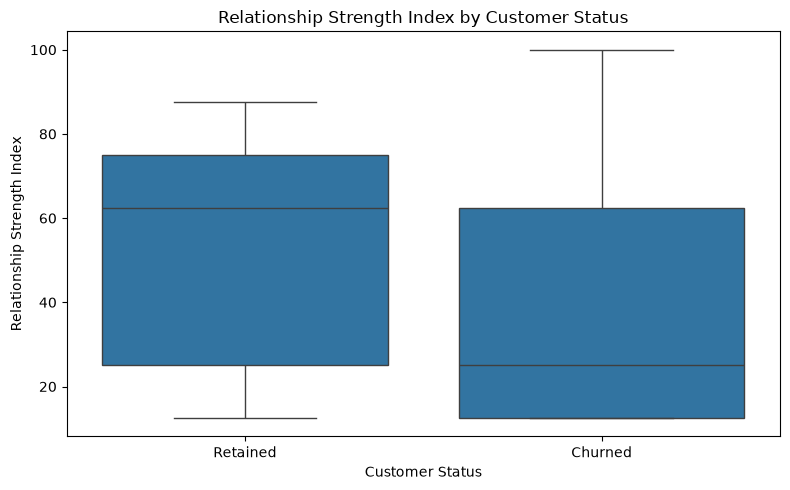

In [33]:
# Visualize relationship strength by customer status

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Relationship_Strength_Index"
)

plt.xticks([0, 1], ["Retained", "Churned"])
plt.title("Relationship Strength Index by Customer Status")
plt.xlabel("Customer Status")
plt.ylabel("Relationship Strength Index")
plt.tight_layout()
plt.savefig(
    output_dir / "06_relationship_strength_by_churn.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [34]:
# KPI 1: Engagement Retention Ratio

active_retention = (
    df.loc[df["IsActiveMember"] == 1, "Exited"] == 0
).mean() * 100

inactive_retention = (
    df.loc[df["IsActiveMember"] == 0, "Exited"] == 0
).mean() * 100

engagement_retention_ratio = (
    active_retention / inactive_retention
    if inactive_retention > 0 else 0
)

print("KPI 1: Engagement Retention Ratio")
print(f"Active customer retention: {active_retention:.2f}%")
print(f"Inactive customer retention: {inactive_retention:.2f}%")
print(f"Engagement retention ratio: {engagement_retention_ratio:.2f}")

KPI 1: Engagement Retention Ratio
Active customer retention: 85.73%
Inactive customer retention: 73.15%
Engagement retention ratio: 1.17


In [35]:
# KPI 2: Product Depth Index

product_depth_index = df.loc[
    df["Exited"] == 0, "NumOfProducts"
].mean()

print("KPI 2: Product Depth Index")
print(f"Average products per retained customer: {product_depth_index:.2f}")

KPI 2: Product Depth Index
Average products per retained customer: 1.54


In [36]:
# KPI 3: High-Balance Disengagement Rate

high_balance_customers = df[df["Balance"] >= balance_threshold]

high_balance_disengagement_rate = (
    (high_balance_customers["IsActiveMember"] == 0).mean() * 100
    if len(high_balance_customers) > 0 else 0
)

print("KPI 3: High-Balance Disengagement Rate")
print(f"High-balance customers: {len(high_balance_customers)}")
print(
    f"Disengagement rate: "
    f"{high_balance_disengagement_rate:.2f}%"
)

KPI 3: High-Balance Disengagement Rate
High-balance customers: 2500
Disengagement rate: 49.88%


In [37]:
# KPI 4: Credit Card Stickiness Score

credit_card_customers = df[df["HasCrCard"] == 1]

credit_card_stickiness_score = (
    (credit_card_customers["Exited"] == 0).mean() * 100
    if len(credit_card_customers) > 0 else 0
)

print("KPI 4: Credit Card Stickiness Score")
print(
    f"Credit card customer retention rate: "
    f"{credit_card_stickiness_score:.2f}%"
)

KPI 4: Credit Card Stickiness Score
Credit card customer retention rate: 79.82%


In [38]:
# Save KPI results for the project

kpi_summary = pd.DataFrame({
    "KPI": [
        "Engagement Retention Ratio",
        "Product Depth Index",
        "High-Balance Disengagement Rate",
        "Credit Card Stickiness Score"
    ],
    "Value": [
        engagement_retention_ratio,
        product_depth_index,
        high_balance_disengagement_rate,
        credit_card_stickiness_score
    ]
})

kpi_summary["Value"] = kpi_summary["Value"].round(2)

kpi_summary.to_csv(output_dir / "kpi_summary.csv", index=False)

kpi_summary

,KPI,Value
0,Engagement Retention Ratio,1.17
1,Product Depth Index,1.54
2,High-Balance Disengagement Rate,49.88
3,Credit Card Stickiness Score,79.82


In [39]:
# Research paper: Dataset summary

print("DATASET SUMMARY")
print("-" * 40)

print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Unique customers:", df["CustomerId"].nunique())

print("\nCUSTOMER STATUS")
print("-" * 40)

print("Retained customers:", (df["Exited"] == 0).sum())
print("Churned customers:", (df["Exited"] == 1).sum())

print(
    "Overall churn rate:",
    round(df["Exited"].mean() * 100, 2),
    "%"
)

print("\nGEOGRAPHICAL DISTRIBUTION")
print("-" * 40)

print(df["Geography"].value_counts())

print("\nPRODUCT DISTRIBUTION")
print("-" * 40)

print(df["NumOfProducts"].value_counts().sort_index())

print("\nENGAGEMENT DISTRIBUTION")
print("-" * 40)

print(df["IsActiveMember"].value_counts().sort_index())

DATASET SUMMARY
----------------------------------------
Total records: 10000
Total columns: 20
Missing values: 0
Duplicate rows: 0
Unique customers: 10000

CUSTOMER STATUS
----------------------------------------
Retained customers: 7963
Churned customers: 2037
Overall churn rate: 20.37 %

GEOGRAPHICAL DISTRIBUTION
----------------------------------------
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

PRODUCT DISTRIBUTION
----------------------------------------
NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

ENGAGEMENT DISTRIBUTION
----------------------------------------
IsActiveMember
0    4849
1    5151
Name: count, dtype: int64


In [40]:
print("Current number of columns:", len(df.columns))
print("\nColumn names:")
print(df.columns.tolist())

Current number of columns: 20

Column names:
['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Product_Category', 'High_Balance', 'Customer_Segment', 'Product_Usage_Score', 'Engagement_Score', 'Relationship_Strength_Index']


In [41]:
# KEY FINDINGS FOR THE RESEARCH PAPER

print("1. CHURN RATE BY ENGAGEMENT")
print("-" * 40)

engagement_results = df.groupby("IsActiveMember").agg(
    Total_Customers=("Exited", "count"),
    Churned_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
)

engagement_results["Churn_Rate"] *= 100

engagement_results.index = [
    "Inactive" if value == 0 else "Active"
    for value in engagement_results.index
]

print(engagement_results.round(2))


print("\n2. CHURN RATE BY NUMBER OF PRODUCTS")
print("-" * 40)

product_results = df.groupby("NumOfProducts").agg(
    Total_Customers=("Exited", "count"),
    Churned_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
)

product_results["Churn_Rate"] *= 100

print(product_results.round(2))


print("\n3. HIGH-BALANCE CUSTOMER ANALYSIS")
print("-" * 40)

high_balance_results = df.groupby("High_Balance").agg(
    Total_Customers=("Exited", "count"),
    Inactive_Customers=("IsActiveMember",
                        lambda x: (x == 0).sum()),
    Churned_Customers=("Exited", "sum"),
    Churn_Rate=("Exited", "mean")
)

high_balance_results["Churn_Rate"] *= 100

high_balance_results.index = [
    "Lower Balance" if value == 0 else "High Balance"
    for value in high_balance_results.index
]

print(high_balance_results.round(2))


print("\n4. RELATIONSHIP STRENGTH INDEX")
print("-" * 40)

rsi_results = df.groupby("Exited")[
    "Relationship_Strength_Index"
].agg(["count", "mean", "median"])

rsi_results.index = [
    "Retained" if value == 0 else "Churned"
    for value in rsi_results.index
]

print(rsi_results.round(2))


print("\n5. CREDIT CARD RETENTION")
print("-" * 40)

card_results = df.groupby("HasCrCard").agg(
    Total_Customers=("Exited", "count"),
    Retained_Customers=(
        "Exited",
        lambda x: (x == 0).sum()
    ),
    Retention_Rate=(
        "Exited",
        lambda x: (x == 0).mean() * 100
    )
)

card_results.index = [
    "No Credit Card" if value == 0 else "Has Credit Card"
    for value in card_results.index
]

print(card_results.round(2))

1. CHURN RATE BY ENGAGEMENT
----------------------------------------
          Total_Customers  Churned_Customers  Churn_Rate
Inactive             4849               1302       26.85
Active               5151                735       14.27

2. CHURN RATE BY NUMBER OF PRODUCTS
----------------------------------------
               Total_Customers  Churned_Customers  Churn_Rate
NumOfProducts                                                
1                         5084               1409       27.71
2                         4590                348        7.58
3                          266                220       82.71
4                           60                 60      100.00

3. HIGH-BALANCE CUSTOMER ANALYSIS
----------------------------------------
               Total_Customers  Inactive_Customers  Churned_Customers  \
Lower Balance             7500                3602               1445   
High Balance              2500                1247                592   

              